# **WATER POTABILITY PROJECT**

# Data Description and Task Overview

## Data Description

This dataset contains measurements of various water quality parameters.Below is a detailed description of each column in the dataset:

Attributes Information
1. **pH**: The pH level of the water.
2. **Hardness**: Water hardness, a measure of mineral content.
3. **Solids**: Total dissolved solids in the water.
4. **Chloramines**: Chloramines concentration in the water.
5. **Sulfate**: Sulfate concentration in the water.
6. **Conductivity**: Electrical conductivity of the water.
7. **Organic_carbon**: Organic carbon content in the water.
8. **Trihalomethanes**: Trihalomethanes concentration in the water.
9. **Turbidity**: Turbidity level, a measure of water clarity.
10. **Potability**: Target variable; indicates water potability with values 1 (potable) and 0 (not potable).

## **Import Necessary Libraries**

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve,accuracy_score,f1_score, precision_score, recall_score,auc
from imblearn.over_sampling import SMOTE

# Models
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier


import warnings
warnings.filterwarnings('ignore')

In [2]:
#Load Dataset
df = pd.read_csv("water_potability.csv")


## 1. **EDA**

In [3]:
print(df.head())

         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0       NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2  8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3  8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4  9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   

   Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       10.379783        86.990970   2.963135           0  
1       15.180013        56.329076   4.500656           0  
2       16.868637        66.420093   3.055934           0  
3       18.436524       100.341674   4.628771           0  
4       11.558279        31.997993   4.075075           0  


In [4]:
df.tail()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1
3275,7.874671,195.102299,17404.177061,7.509306,NaN,327.459760,16.140368,78.698446,2.309149,1


In [5]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB
None


In [6]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [7]:
df.shape 

(3276, 10)

In [8]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Potability'].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

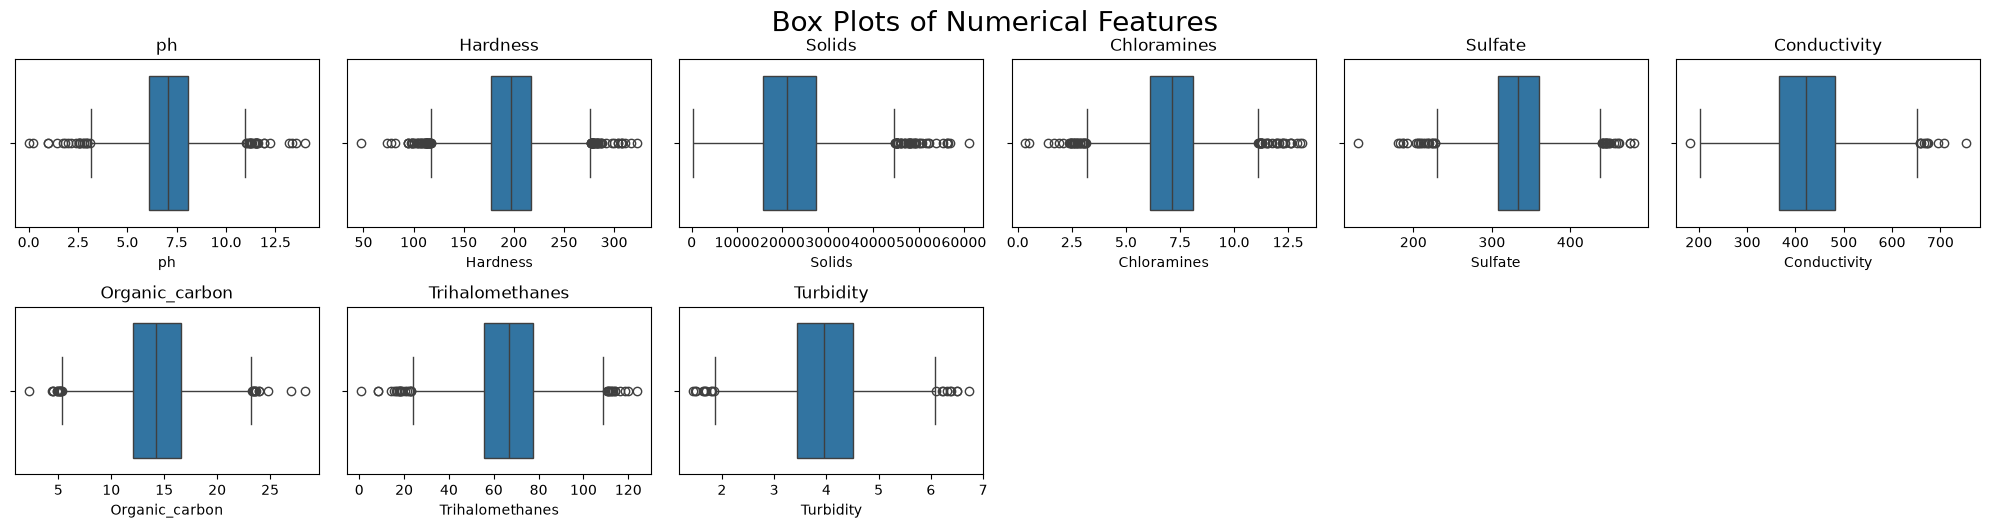

In [11]:
# Plot box plots for numerical features
x_values = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']
plt.figure(figsize=(20, 15))
for i, column in enumerate(df[x_values], 1):    
     plt.subplot(6, 6, i)     
     sns.boxplot(data=df[x_values], x=column)    
     plt.title(column)

plt.suptitle('Box Plots of Numerical Features', fontsize=20)
plt.tight_layout()
plt.show()

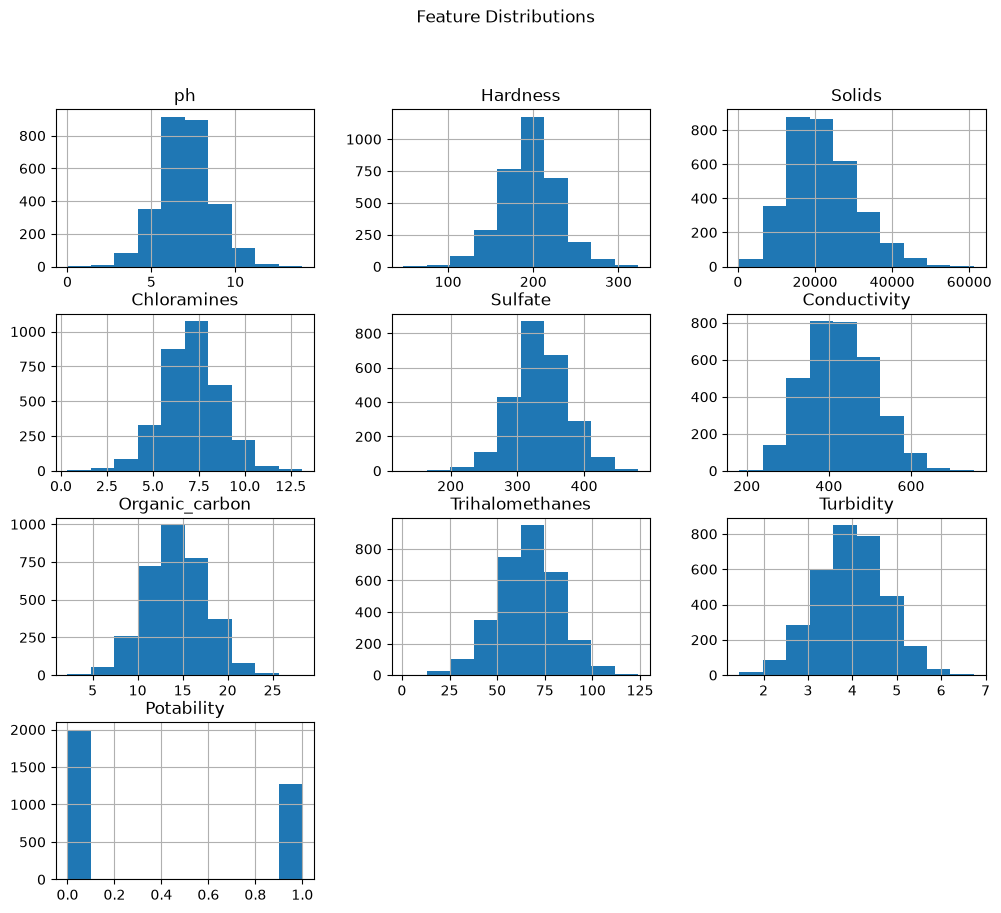

In [12]:
# Distribution plots
df.hist(figsize=(12,10))
plt.suptitle("Feature Distributions")
plt.show()

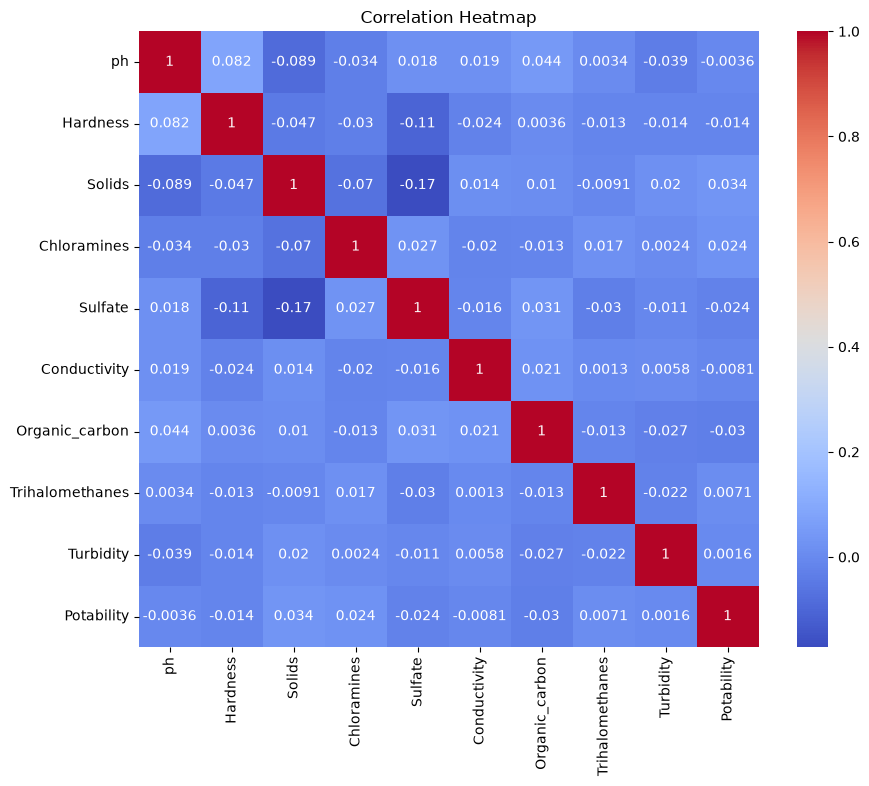

In [13]:
# Correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

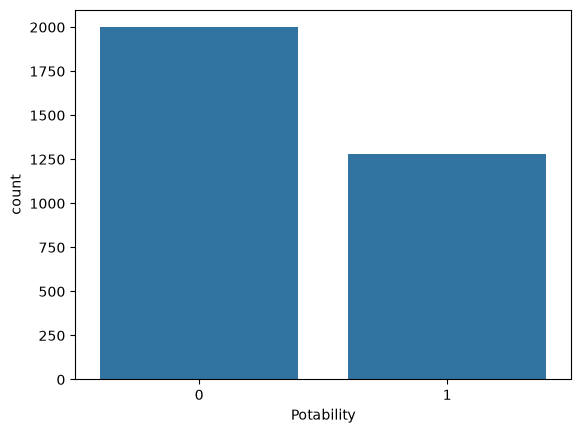

In [14]:
#check imbalane data
sns.countplot(x='Potability', data=df)
plt.show()

# **2. Data Cleaning and Preprocessing**

**Handle Missing Values**

In [15]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [16]:
#Handle Missing Values
df = df.fillna(df.mean())

In [17]:
df.isnull().sum()


ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

**Handle Outliers**

In [18]:
def cap_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap values instead of removing
    data[column] = np.where(data[column] < lower_bound, lower_bound, data[column])
    data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])
    return data

# Apply to all numeric columns
for col in df.select_dtypes(include=['float64','int64']).columns:
    df = cap_outliers_iqr(df, col)

print("Outlier capping completed!")



Outlier capping completed!


In [19]:
# Features & Target
X = df.drop("Potability", axis=1)
y = df["Potability"]

## **3.Train Test Split**

In [20]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

## **4.Feature Scaling**

In [21]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



**Balancing Data using Smote**

In [22]:
print(X_train.shape)   # should be (rows, columns)
print(y_train.shape)   # should be (rows,)


(2620, 9)
(2620,)


In [23]:
# Step 8: Handle Class Imbalance
from collections import Counter


print("Before SMOTE:", Counter(y_train))
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("After SMOTE:", Counter(y_train_resampled))

Before SMOTE: Counter({0.0: 1598, 1.0: 1022})
After SMOTE: Counter({0.0: 1598, 1.0: 1598})


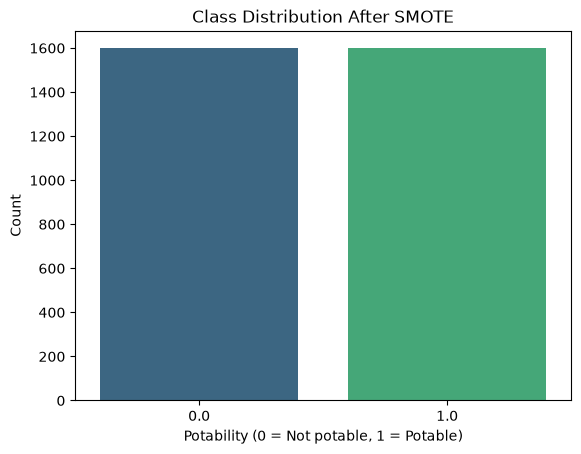

In [24]:
# Convert to DataFrame for plotting
smote_counts = Counter(y_train_resampled)
smote_df = pd.DataFrame.from_dict(smote_counts, orient='index').reset_index()
smote_df.columns = ['Potability', 'Count']

# Plot histogram/bar chart
sns.barplot(x='Potability', y='Count', data=smote_df, palette='viridis')
plt.title("Class Distribution After SMOTE")
plt.xlabel("Potability (0 = Not potable, 1 = Potable)")
plt.ylabel("Count")
plt.show()

## **5.Model Developement**

**List of Models**

- Support Vector Machine
- Random Forest
- K-Nearest Neigbour
- Decision Tree
- XG Boost Classifier

In [25]:
# 1. Support Vector Machine
svm = SVC()
svm.fit(X_train_resampled, y_train_resampled)

# 2. Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_resampled, y_train_resampled)

# 3. K-Nearest Neighbors
knn = KNeighborsClassifier()
knn.fit(X_train_resampled, y_train_resampled)

# 4. Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_resampled, y_train_resampled)

# 5. XGBoost Classifier
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_resampled, y_train_resampled)

print("All models trained successfully!")
models={
    "SVM": svm,
    "Random Forest": rf,
    "KNN": knn,
    "Decision Tree": dt,
    "XGBoost": xgb
}
for name, model in models.items():
    y_pred=model.predict(X_test)
    scores = cross_val_score(model, X_train_resampled, y_train_resampled, cv=5, scoring="accuracy")
    print(f"{name} CV Accuracy: {scores.mean():.4f}")

All models trained successfully!
SVM CV Accuracy: 0.5038
Random Forest CV Accuracy: 0.6990
KNN CV Accuracy: 0.5886
Decision Tree CV Accuracy: 0.6101
XGBoost CV Accuracy: 0.6705


## **6.Hyperparameter Tuning**

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
model = RandomForestClassifier(random_state=42)

# Hyperparameters to reduce overfitting
hyper_parameters = {
    'n_estimators': [100, 200],
    'max_depth': [5, 8, 10],
    'min_samples_split': [10, 20, 30],
    'min_samples_leaf': [5, 10, 15],
    'max_features': ['sqrt'],
    'max_samples': [0.7, 0.8]
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=hyper_parameters,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Train the model
grid_search.fit(X_train, y_train)

# Best model
best_rf = grid_search.best_estimator_

# Predictions
y_pred = best_rf.predict(X_test)

# Results
print("Training Accuracy:", accuracy_score(y_train, best_rf.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, y_pred))



Fitting 3 folds for each of 108 candidates, totalling 324 fits
Training Accuracy: 0.7725190839694657
Testing Accuracy: 0.6646341463414634


## **7.Evaluate Tuned Model**

In [27]:
#Evaluate Tuned Model

# Accuracy
print("Random Forest Results:")
print("Accuracy:", accuracy_score(y_test, y_pred))

# Best Cross-Validation Score
print("Best CV Score:", grid_search.best_score_)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest Results:
Accuracy: 0.6646341463414634
Best CV Score: 0.6603058270707897

Classification Report:
              precision    recall  f1-score   support

         0.0       0.66      0.94      0.77       400
         1.0       0.72      0.23      0.35       256

    accuracy                           0.66       656
   macro avg       0.69      0.59      0.56       656
weighted avg       0.68      0.66      0.61       656

Confusion Matrix:
[[377  23]
 [197  59]]


## **8.Confusion Matrix and ROC curve**

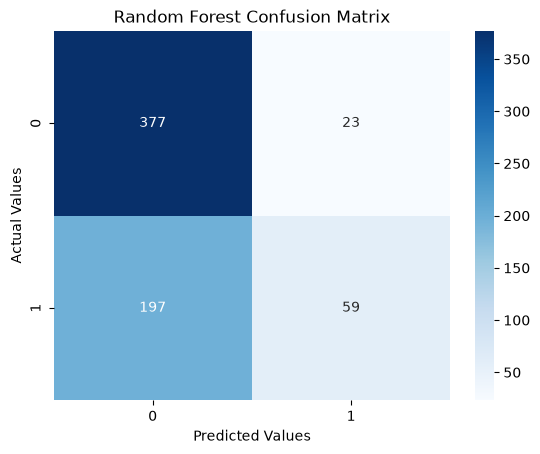

In [28]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()



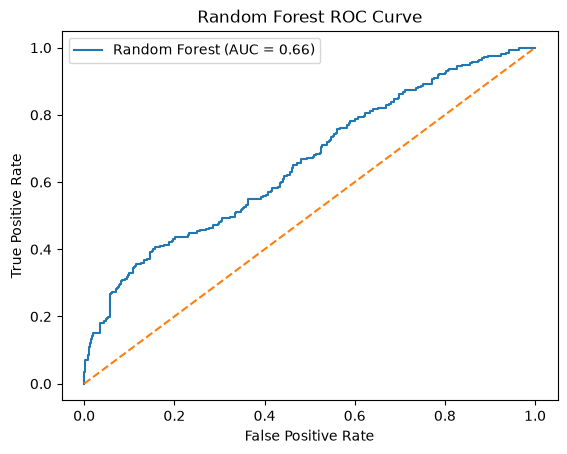

In [29]:
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import auc


y_pred_prob = best_rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.show()


## **8.Feature Importance**

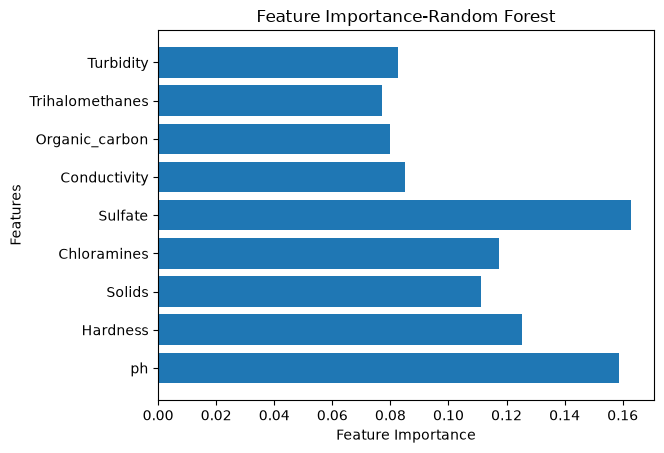

In [30]:
importance = best_rf.feature_importances_

plt.barh(X_train.columns, importance)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance-Random Forest")
plt.show()